# L19 · Tool calling con una API externa: la TRM del día

*Advanced Topics in Analytics II - Generative AI* · Instructor: Sergio A. Mora Pardo

En [L13](L13-tools.ipynb) las herramientas leían diccionarios escritos en el notebook. Ahora la herramienta consulta una **API pública real**: la **tasa representativa del mercado (TRM)** de Colombia, publicada como datos abiertos en [datos.gov.co](https://www.datos.gov.co/), gratuita y sin clave. Los créditos de **ACME** se pagan en pesos, y un cliente que recibe dinero en dólares quiere saber cuántos pesos son.

Seguimos haciendo **function calling** (o *tool calling*): el modelo propone qué función llamar y con qué argumentos, y nuestro código la ejecuta. El ciclo **modelo → herramienta → modelo** no cambia. Lo nuevo está dentro de la función: la red, los tiempos de espera, los errores de la API y datos que cambian cada día.

## Objetivos

Al terminar podrás:

1. Llamar una API HTTP con `httpx` y leer su respuesta JSON.
2. Envolver la API en una herramienta que devuelve los errores de red y de la API como datos.
3. Explicar por qué, para el modelo, una herramienta que llama una API es igual que una que lee un diccionario.
4. Comprobar la respuesta de un agente cuando los datos cambian cada día.

## Metodología

- **Primero sin modelo.** Las secciones 1, 2 y 4 no llaman a Claude: la API y la herramienta se prueban directamente.
- **Datos vivos.** La TRM cambia cada día hábil, así que no hay una cifra fija que esperar: se compara la respuesta con lo que devolvió la herramienta en *esta* ejecución.

## Contenido

- [0. Preparación del modelo](#0.-Preparación-del-modelo)
- [1. La API sin modelo](#1.-La-API-sin-modelo)
- [2. La API como herramienta](#2.-La-API-como-herramienta)
- [3. El agente consulta la API](#3.-El-agente-consulta-la-API)
- [4. Comprobar la respuesta con datos que cambian](#4.-Comprobar-la-respuesta-con-datos-que-cambian)
- [5. Una condición del prompt cambia la conducta](#5.-Una-condición-del-prompt-cambia-la-conducta)
- [Práctica breve](#Práctica-breve)
- [Referencias](#Referencias)

**Preparación:** la misma de L13. Además, el equipo necesita salida a internet hacia `www.datos.gov.co`.

El recorrido realiza **unas 5 llamadas a Claude Haiku** en las secciones 3 y 5. Repetir celdas consume tokens; las consultas a datos.gov.co son gratuitas.

## 0. Preparación del modelo

Igual que en L13. Con `LANGSMITH_TRACING=true` en `.env`, un recorrido completo genera **3 trazas**, una por cada `agent.invoke`.

In [ ]:
import os

from dotenv import find_dotenv, load_dotenv
from langchain_anthropic import ChatAnthropic

# find_dotenv sube por las carpetas hasta encontrar el .env de la raíz
load_dotenv(find_dotenv())

model = ChatAnthropic(
    model="claude-haiku-5-5",
    max_tokens=400,
    thinking={"type": "disabled"},
    timeout=60,
    max_retries=2,
)
print("Trazas en LangSmith:", os.getenv("LANGSMITH_TRACING", "false"))

## 1. La API sin modelo

Una API web se consulta con una petición HTTP: una **URL**, unos **parámetros** y una respuesta, casi siempre en JSON. El conjunto de datos de la TRM en datos.gov.co se consulta con parámetros que empiezan por `$`: `$order` ordena y `$limit` limita el número de filas. Cada fila trae el valor (`valor`), la unidad y el periodo en que rige (`vigenciadesde` y `vigenciahasta`).

In [ ]:
import httpx

TRM_URL = "https://www.datos.gov.co/resource/32sa-8pi3.json"

response = httpx.get(TRM_URL, params={"$order": "vigenciadesde DESC", "$limit": 3}, timeout=15)
print("Código HTTP:", response.status_code)
response.json()

Fíjate en las fechas: una TRM puede regir varios días, por ejemplo de un sábado a un lunes. Tus cifras serán distintas a las de tus compañeros si ejecutan otro día.

Las APIs también fallan. Si ordenamos por una columna que no existe, la API responde con un **código 400** y explica el motivo en el JSON. Lo fiable es el código HTTP; el mensaje de una API externa puede cambiar sin aviso.

In [ ]:
bad_response = httpx.get(TRM_URL, params={"$order": "precio DESC", "$limit": 1}, timeout=15)
print("Código HTTP:", bad_response.status_code)
bad_response.json()["message"][:200]

## 2. La API como herramienta

`get_exchange_rate` busca la TRM que rige en una fecha. Igual que `lookup_credit` en L13, **no lanza errores**: devuelve un diccionario con `status`.

- `not_found`: no hay TRM publicada para esa fecha (por ejemplo, una fecha futura).
- `unavailable`: la API respondió con error o no respondió. El `timeout` evita que el agente se quede esperando.
- `ok`: el valor, el periodo en que rige y la fuente.

In [ ]:
from langchain_core.tools import tool


@tool(parse_docstring=True)
def get_exchange_rate(date: str) -> dict:
    """Consulta la TRM (pesos colombianos por dólar) que rige en una fecha, en los datos abiertos de datos.gov.co.

    Args:
        date: fecha en formato AAAA-MM-DD.
    """
    where = f"vigenciadesde <= '{date}T00:00:00' AND vigenciahasta >= '{date}T00:00:00'"
    try:
        response = httpx.get(TRM_URL, params={"$where": where, "$limit": 1}, timeout=15)
    except httpx.HTTPError as error:
        return {"status": "unavailable", "message": f"datos.gov.co no respondió: {error}"}
    if response.is_error:
        return {"status": "unavailable", "message": response.text[:300]}
    rows = response.json()
    if not rows:
        return {"status": "not_found", "message": f"No hay TRM publicada para {date}."}
    row = rows[0]
    return {
        "status": "ok",
        "date": date,
        "cop_per_usd": float(row["valor"]),
        "valid_from": row["vigenciadesde"][:10],
        "valid_to": row["vigenciahasta"][:10],
        "source": "datos.gov.co · TRM",
    }

In [ ]:
from datetime import date

today = date.today().isoformat()
get_exchange_rate.invoke({"date": today})

Los dos errores llegan como datos: una fecha sin TRM publicada y una fecha mal escrita, que la API rechaza.

In [ ]:
future_rate = get_exchange_rate.invoke({"date": "2099-01-01"})
bad_date = get_exchange_rate.invoke({"date": "mañana"})
print(future_rate)
print(bad_date)

## 3. El agente consulta la API

Para el agente no cambia nada: ve un nombre, una descripción y unos argumentos. **No sabe que detrás hay una API**; eso solo lo sabe nuestro código.

El modelo no sabe qué día es hoy, así que lo incluimos en el *system prompt*. Sin esa fecha no podría pedir la TRM «de hoy». El *system prompt* es una plantilla Jinja, como en L12: recibe la fecha y usa `{% if %}` para la regla de la fecha por defecto. Con `default_today=True`, el agente usa la TRM de hoy cuando la pregunta no dice la fecha; sin ella, pregunta cuál.

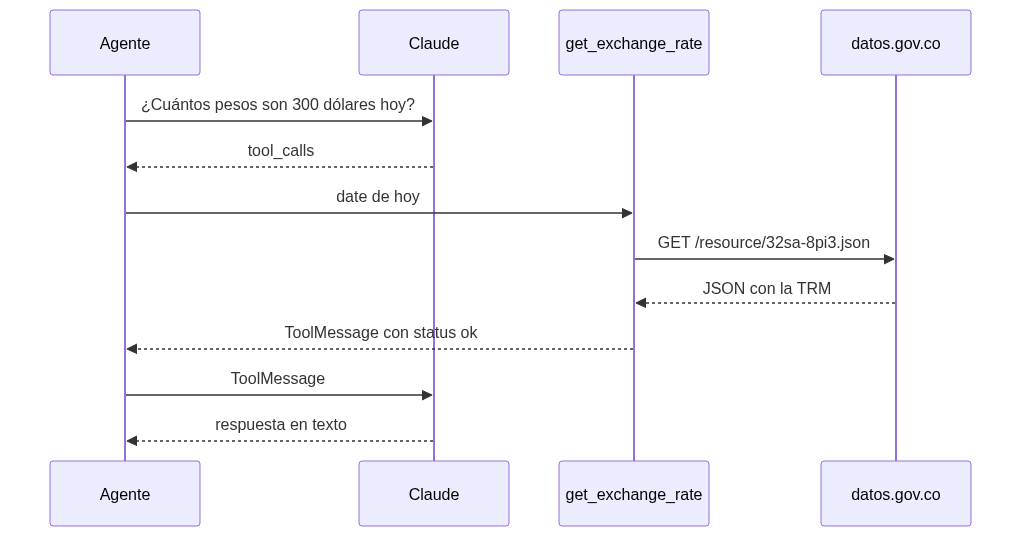

<details><summary>Código Mermaid</summary>

```mermaid
sequenceDiagram
    participant A as Agente
    participant M as Claude
    participant T as get_exchange_rate
    participant O as datos.gov.co
    A->>M: ¿Cuántos pesos son 300 dólares hoy?
    M-->>A: tool_calls
    A->>T: date de hoy
    T->>O: GET /resource/32sa-8pi3.json
    O-->>T: JSON con la TRM
    T-->>A: ToolMessage con status ok
    A->>M: ToolMessage
    M-->>A: respuesta en texto
```

</details>

In [ ]:
from jinja2 import Environment, StrictUndefined
from langchain.agents import create_agent
from langchain_core.messages import HumanMessage

AGENT_TEMPLATE = """\
Hoy es {{ today }}.
Eres el asistente de soporte de ACME, una fintech. Responde siempre en español.
Los créditos de ACME se pagan en pesos colombianos (COP).
Consulta la TRM con la herramienta y usa solo las cifras que devuelve; muestra la cuenta que haces.
Si la herramienta no encuentra un dato o no está disponible, dilo.
{% if default_today %}
Si la pregunta no indica la fecha, usa la TRM de hoy y dilo en la respuesta.
{% else %}
Si la pregunta no indica la fecha, pregunta cuál antes de consultar.
{% endif %}
"""
agent_template = Environment(undefined=StrictUndefined, trim_blocks=True, lstrip_blocks=True).from_string(AGENT_TEMPLATE)

SYSTEM_PROMPT = agent_template.render(today=today, default_today=True)
print(SYSTEM_PROMPT)

fx_agent = create_agent(model, tools=[get_exchange_rate], system_prompt=SYSTEM_PROMPT)
fx_result = fx_agent.invoke(
    {"messages": [HumanMessage("Me llegaron 300 dólares de una remesa hoy. ¿Cuántos pesos son con la TRM de hoy?")]}
)

for message in fx_result["messages"]:
    message.pretty_print()

## 4. Comprobar la respuesta con datos que cambian

En L13 sabíamos que la respuesta debía decir 324.000 pesos. Aquí no hay cifra fija: la comprobamos contra el `ToolMessage` de **esta** ejecución. Esta sección no llama al modelo.

Calculamos nosotros los pesos con la TRM que devolvió la herramienta y buscamos la parte entera en el texto final, comparando solo los dígitos. El modelo puede redondear distinto, así que una falla se revisa leyendo los mensajes.

In [ ]:
import json
import re

rate_data = [json.loads(m.content) for m in fx_result["messages"] if m.type == "tool"][-1]
fx_answer = fx_result["messages"][-1].text
expected_cop = int(300 * rate_data["cop_per_usd"])

print("Fuente:", rate_data["source"], "| status:", rate_data["status"], "| TRM:", rate_data["cop_per_usd"])
print("300 USD en pesos (nuestra cuenta):", expected_cop)
print("¿La respuesta trae esa cifra?", str(expected_cop) in re.sub(r"[^\d]", "", fx_answer))

## 5. Una condición del prompt cambia la conducta

La plantilla tiene un `{% if default_today %}`. Hacemos la misma pregunta **sin decir la fecha** con dos versiones del *system prompt*:

- Con `default_today=True`, la regla dice que use la TRM de hoy y lo avise.
- Con `default_today=False`, la regla dice que pregunte la fecha antes de consultar.

Para cada versión imprimimos la regla que entró en el prompt, las herramientas que pidió el agente y su respuesta.

In [ ]:
undated_question = "¿Cuántos pesos son 150 dólares?"
undated_results = {}

for default_today in (True, False):
    prompt = agent_template.render(today=today, default_today=default_today)
    agent = create_agent(model, tools=[get_exchange_rate], system_prompt=prompt)
    undated_results[default_today] = agent.invoke({"messages": [HumanMessage(undated_question)]})

    messages = undated_results[default_today]["messages"]
    calls = [call["args"] for m in messages if m.type == "ai" for call in m.tool_calls]
    print(f"===== default_today={default_today}")
    print("Regla en el prompt:", prompt.strip().splitlines()[-1])
    print("Herramientas pedidas:", calls)
    print("Respuesta:", messages[-1].text)
    print()

Con la fecha por defecto, el agente consulta la TRM de hoy y lo dice. Sin ella, no adivina: pregunta la fecha antes de llamar la herramienta. Es la misma idea de L12 con la fecha de los cargos: una condición en la plantilla decide qué instrucción recibe el modelo.

## Práctica breve

1. Pregunta al agente por la TRM del último viernes y comprueba con la sección 4 que la cifra coincide. ¿Qué periodo de vigencia devuelve la herramienta?
2. Pide la TRM de una fecha del próximo año. ¿Qué devuelve la herramienta y qué responde el agente?
3. Agrega a `create_agent` la herramienta `lookup_credit` de L13 y pregunta: *«Soy el cliente C-1042 y me llegaron 300 dólares, ¿con eso me pongo al día?»*. ¿Usa las dos herramientas?
4. Busca otro conjunto de datos abiertos sin clave en datos.gov.co que le sirva a ACME. Envuélvelo en una herramienta que devuelva los errores como datos y pruébala sin modelo, como en la sección 2.

## Referencias

- [TRM en datos abiertos de Colombia](https://www.datos.gov.co/d/32sa-8pi3): el conjunto de datos y sus columnas.
- [API de Socrata (SODA)](https://dev.socrata.com/docs/queries/): los parámetros `$where`, `$order` y `$limit`.
- [Herramientas en LangChain](https://docs.langchain.com/oss/python/langchain/tools) · [`httpx`](https://www.python-httpx.org/)